---
title: "Characteristic-Wise WENO-Z for Euler Shocks"
date: 2026-10-14
categories: [high-order methods, WENO, compressible flow]
description: "Compare component-wise and Roe-characteristic WENO-Z reconstruction on fixed-grid Euler tests."
---

# Characteristic-Wise WENO-Z for Euler Shocks
### Same nonlinear stencil logic, different reconstruction space

**Learning goal:** Implement fifth-order WENO-Z state reconstruction in both conservative-component and Roe-characteristic variables, then quantify how reconstruction space changes oscillation control, contact/entropy-wave resolution, conservation, and robustness.

**Time:** 60-90 minutes. Python, NumPy, Matplotlib. Use the prescribed fixed grids only; this is not a grid-refinement or order-estimation exercise.

You already know the basic WENO machinery. The focus here is the production-solver decision: where the nonlinear weights are computed, how the characteristic basis is frozen at an interface, and what diagnostics distinguish a clean-looking answer from a trustworthy one.

## 1. Governing model and reference solution

Solve the one-dimensional Euler equations
$$U_t+F(U)_x=0,\qquad U=[\rho,\rho u,E]^T,$$
$$F(U)=[\rho u,\rho u^2+p,u(E+p)]^T,\qquad p=(\gamma-1)\left(E-\tfrac12\rho u^2\right),$$
with $\gamma=1.4$ (units: $\rho$ in mass/length$^3$, $u$ in length/time, $p$ and $E$ in energy/volume). Advance cell averages using
$$\frac{dU_i}{dt}=-\frac{\hat F_{i+1/2}-\hat F_{i-1/2}}{\Delta x}$$
and SSPRK(3,3). Set each time step from the maximum local signal speed $|u|+c$ and CFL = 0.35. Use three transmissive ghost cells on each side.

At an interface, reconstruct left/right conservative states and evaluate a local Rusanov flux. Keep flux evaluation identical between methods so reconstruction space is the only controlled difference.

There is no closed-form exact solution to compare against here; instead the two fixed-grid cases used throughout this notebook (Lax shock tube, Shu-Osher shock-entropy interaction, defined in Section 3) are standard, well-documented WENO benchmarks from Shu's ICASE/NASA report (see Section 7 references), so their qualitative wave structure — shock, contact, and post-shock entropy waves — is the reference against which both reconstruction spaces are judged.

In [1]:
import sys
import time

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

GAMMA = 1.4
CFL = 0.35
RHO_FLOOR = 1.0e-12
P_FLOOR = 1.0e-12
EPS_WENO = 1.0e-40

np.set_printoptions(precision=6, suppress=True)
np.random.seed(0)

print(f"python {sys.version.split()[0]}, numpy {np.__version__}, matplotlib {plt.matplotlib.__version__}")

python 3.12.3, numpy 2.5.2, matplotlib 3.11.1


## 2. Discretization and conditions

The spatial operator is built from three pieces, implemented in turn below: the scalar WENO-Z stencil, the choice of reconstruction space it is applied in, and the flux/time-integration/fallback machinery that uses it.

### WENO-Z scalar reconstruction

Implement the standard three third-order candidate polynomials and Jiang-Shu smoothness indicators $\beta_0,\beta_1,\beta_2$ for a fifth-order left-biased interface value. Use optimal weights $d=(0.1,0.6,0.3)$ and WENO-Z weights
$$\tau_5=|\beta_0-\beta_2|,\qquad
\alpha_k=d_k\left[1+\left(\frac{\tau_5}{\beta_k+\epsilon}\right)^2\right],\qquad
\omega_k=\frac{\alpha_k}{\sum_j\alpha_j}.$$

Obtain the right-biased reconstruction by symmetry, not a second unrelated formula. Return both the reconstructed value and weights so the nonlinear stencil choice can be inspected. Unit-test constant, linear, and mirrored stencil behavior before using Euler states.

In [2]:
def weno_z_left(v5, eps=EPS_WENO):
    """Fifth-order WENO-Z left-biased interface value from a length-5 scalar
    stencil (v0..v4). Works elementwise if the last axis of ``v5`` has length
    5, so it also accepts a batch of stencils with shape (..., 5). Returns
    the reconstructed value and the three nonlinear weights."""
    v5 = np.asarray(v5)
    v0, v1, v2, v3, v4 = v5[..., 0], v5[..., 1], v5[..., 2], v5[..., 3], v5[..., 4]
    p0 = (2 * v0 - 7 * v1 + 11 * v2) / 6.0
    p1 = (-v1 + 5 * v2 + 2 * v3) / 6.0
    p2 = (2 * v2 + 5 * v3 - v4) / 6.0
    beta0 = 13.0 / 12.0 * (v0 - 2 * v1 + v2) ** 2 + 0.25 * (v0 - 4 * v1 + 3 * v2) ** 2
    beta1 = 13.0 / 12.0 * (v1 - 2 * v2 + v3) ** 2 + 0.25 * (v1 - v3) ** 2
    beta2 = 13.0 / 12.0 * (v2 - 2 * v3 + v4) ** 2 + 0.25 * (3 * v2 - 4 * v3 + v4) ** 2
    d0, d1, d2 = 0.1, 0.6, 0.3
    tau5 = np.abs(beta0 - beta2)
    a0 = d0 * (1 + (tau5 / (beta0 + eps)) ** 2)
    a1 = d1 * (1 + (tau5 / (beta1 + eps)) ** 2)
    a2 = d2 * (1 + (tau5 / (beta2 + eps)) ** 2)
    s = a0 + a1 + a2
    w0, w1, w2 = a0 / s, a1 / s, a2 / s
    val = w0 * p0 + w1 * p1 + w2 * p2
    return val, np.stack([w0, w1, w2], axis=-1)


def weno_z_right(v5, eps=EPS_WENO):
    """Right-biased value obtained by mirroring the stencil through weno_z_left."""
    v5 = np.asarray(v5)
    val, w = weno_z_left(v5[..., ::-1], eps)
    return val, w[..., ::-1]


# --- unit tests: constant, linear, mirror symmetry ---
const5 = np.array([3.0, 3.0, 3.0, 3.0, 3.0])
val_l, _ = weno_z_left(const5)
val_r, _ = weno_z_right(const5)
assert abs(val_l - 3.0) < 1e-13 and abs(val_r - 3.0) < 1e-13, "constant reconstruction failed"

lin5 = np.array([1.0, 2.0, 3.0, 4.0, 5.0])
val_lin, _ = weno_z_left(lin5)
assert abs(val_lin - 3.5) < 1e-10, "linear stencil should reconstruct exactly"

mix5 = np.array([1.0, 2.5, 1.8, 3.2, 0.5])
val_a, _ = weno_z_left(mix5)
val_b, _ = weno_z_right(mix5[::-1])
assert abs(val_a - val_b) < 1e-13, "mirror symmetry failed"

print("WENO-Z scalar unit tests passed (constant, linear, mirror symmetry).")

WENO-Z scalar unit tests passed (constant, linear, mirror symmetry).


### Two reconstruction spaces

**Component-wise:** Apply scalar WENO-Z independently to the three conservative components on each interface stencil.

**Characteristic-wise:** At every interface, compute a Roe-averaged state from the adjacent cell averages, construct right and left eigenvector matrices $R$ and $L=R^{-1}$ for the Euler flux Jacobian, and freeze this basis across the full five-point stencil. Project each stencil vector with $w_j=LU_j$, reconstruct each characteristic component, then return with $U^\pm=Rw^\pm$.

Verify numerically that $LR\approx I$, eigenvalues are $\tilde u-\tilde c,\tilde u,\tilde u+\tilde c$, and both methods exactly preserve a constant state. Do not recompute a different eigenbasis at every stencil point; that destroys the intended local characteristic projection.

In [3]:
def primitive_to_conservative(rho, u, p):
    """Convert primitive (rho, u, p) to conservative U=[rho, rho*u, E]."""
    E = p / (GAMMA - 1.0) + 0.5 * rho * u * u
    return np.array([rho, rho * u, E])


def conservative_to_primitive(U):
    """Return rho, u, p, c from conservative state(s) U, floored to stay
    physical (rho, p clipped to the floors defined above)."""
    U = np.asarray(U)
    rho = np.maximum(U[..., 0], RHO_FLOOR)
    u = U[..., 1] / rho
    p = np.maximum((GAMMA - 1.0) * (U[..., 2] - 0.5 * rho * u * u), P_FLOOR)
    c = np.sqrt(GAMMA * p / rho)
    return rho, u, p, c


def roe_eigenvectors(UL, UR):
    """Roe-averaged eigenvalues, right eigenvectors R, and left eigenvectors
    L=R^-1 of the Euler flux Jacobian at one interface (UL, UR each length
    3), or batched over a leading axis if UL, UR have shape (M, 3)."""
    single = UL.ndim == 1
    UL = np.atleast_2d(UL)
    UR = np.atleast_2d(UR)
    rhoL, uL, pL, cL = conservative_to_primitive(UL)
    rhoR, uR, pR, cR = conservative_to_primitive(UR)
    HL = (UL[..., 2] + pL) / rhoL
    HR = (UR[..., 2] + pR) / rhoR
    sqL, sqR = np.sqrt(rhoL), np.sqrt(rhoR)
    u = (sqL * uL + sqR * uR) / (sqL + sqR)
    H = (sqL * HL + sqR * HR) / (sqL + sqR)
    c = np.sqrt((GAMMA - 1.0) * (H - 0.5 * u * u))
    eig = np.stack([u - c, u, u + c], axis=-1)

    M = UL.shape[0]
    R = np.zeros((M, 3, 3))
    L = np.zeros((M, 3, 3))
    R[:, 0, 0] = R[:, 0, 1] = R[:, 0, 2] = 1.0
    R[:, 1, 0], R[:, 1, 1], R[:, 1, 2] = u - c, u, u + c
    R[:, 2, 0], R[:, 2, 1], R[:, 2, 2] = H - u * c, 0.5 * u * u, H + u * c
    b2 = (GAMMA - 1.0) / c ** 2
    b1 = b2 * 0.5 * u * u
    L[:, 0, 0], L[:, 0, 1], L[:, 0, 2] = 0.5 * (b1 + u / c), -0.5 * (b2 * u + 1.0 / c), 0.5 * b2
    L[:, 1, 0], L[:, 1, 1], L[:, 1, 2] = 1.0 - b1, b2 * u, -b2
    L[:, 2, 0], L[:, 2, 1], L[:, 2, 2] = 0.5 * (b1 - u / c), -0.5 * (b2 * u - 1.0 / c), 0.5 * b2

    if single:
        return eig[0], R[0], L[0]
    return eig, R, L


NG = 3  # transmissive ghost cells each side


def _stencil(col, n_int, left_offset):
    """5-wide sliding-window stencil matrix (n_int, 5): row k holds the 5
    cells starting left_offset cells before the left cell of interface k."""
    i0 = NG - 3 + left_offset
    return np.stack([col[i0 + j: i0 + j + n_int] for j in range(5)], axis=-1)


def reconstruct_interfaces(Ug, mode, want_weights=False):
    """Reconstruct UL, UR at every physical interface from ghost-padded cell
    averages Ug (shape (N+2*NG, 3)). mode is 'component' or 'characteristic'.
    Returns UL, UR (each (N+1, 3)) and, if want_weights, the left-biased
    nonlinear weights per interface and field, shape (N+1, 3, 3)."""
    n_phys = Ug.shape[0] - 2 * NG
    n_int = n_phys + 1
    weights = np.zeros((n_int, 3, 3)) if want_weights else None

    if mode == "component":
        ULs = np.zeros((n_int, 3))
        URs = np.zeros((n_int, 3))
        for c in range(3):
            vl, wl = weno_z_left(_stencil(Ug[:, c], n_int, 0))
            vr, _ = weno_z_right(_stencil(Ug[:, c], n_int, 1))
            ULs[:, c] = vl
            URs[:, c] = vr
            if want_weights:
                weights[:, c, :] = wl
        return ULs, URs, weights

    if mode == "characteristic":
        i_left = np.arange(NG - 1, NG - 1 + n_int)
        _, R, L = roe_eigenvectors(Ug[i_left], Ug[i_left + 1])
        stencilL = np.stack([Ug[i_left - 2 + j] for j in range(5)], axis=1)  # (n_int,5,3)
        stencilR = np.stack([Ug[i_left - 1 + j] for j in range(5)], axis=1)
        wL = np.einsum("nsj,nij->nsi", stencilL, L)  # project stencil onto characteristic fields
        wR = np.einsum("nsj,nij->nsi", stencilR, L)
        wl_char = np.zeros((n_int, 3))
        wr_char = np.zeros((n_int, 3))
        for c in range(3):
            vl, wl = weno_z_left(wL[:, :, c])
            vr, _ = weno_z_right(wR[:, :, c])
            wl_char[:, c] = vl
            wr_char[:, c] = vr
            if want_weights:
                weights[:, c, :] = wl
        ULs = np.einsum("nij,nj->ni", R, wl_char)
        URs = np.einsum("nij,nj->ni", R, wr_char)
        return ULs, URs, weights

    raise ValueError(mode)


# --- verify LR ~ I and Roe eigenstructure on 20 seeded physical state pairs ---
rng = np.random.default_rng(0)
rho_s = rng.uniform(0.2, 5.0, size=(20, 2))
u_s = rng.uniform(-3.0, 3.0, size=(20, 2))
p_s = rng.uniform(0.2, 10.0, size=(20, 2))
UL_s = np.array([primitive_to_conservative(rho_s[i, 0], u_s[i, 0], p_s[i, 0]) for i in range(20)])
UR_s = np.array([primitive_to_conservative(rho_s[i, 1], u_s[i, 1], p_s[i, 1]) for i in range(20)])
eig_s, R_s, L_s = roe_eigenvectors(UL_s, UR_s)
lr_err = np.max(np.abs(np.einsum("mij,mjk->mik", L_s, R_s) - np.eye(3)))
assert lr_err < 1e-12, lr_err
print(f"max |LR - I| over 20 seeded Roe states: {lr_err:.3e}")

max |LR - I| over 20 seeded Roe states: 4.441e-16


### Flux evaluation, time integration, and admissibility fallback

Use the local Rusanov flux
$$\hat F(U^-,U^+)=\tfrac12[F(U^-)+F(U^+)]-\tfrac12a_{max}(U^+-U^-),$$
where $a_{max}=\max(|u^-|+c^-,|u^+|+c^+)$. Advance with SSPRK(3,3).

At each RK stage, first attempt the WENO-Z spatial operator. If any candidate stage has nonfinite values, $\rho\le\rho_{floor}$, or $p\le p_{floor}$, repeat that entire stage using piecewise-constant states with the same Rusanov flux. Count and report every fallback. This coarse stage-level mechanism is intentionally transparent; it is a safety net, not a claim of high-order positivity preservation.

Track total mass, momentum, and energy after every accepted full step. With transmissive boundaries, interpret conservation changes using net boundary flux, not an unjustified zero-drift assertion. Because SSPRK(3,3) is a convex combination of forward-Euler stages and each stage is exactly conservative (a telescoping flux difference), the domain-integrated conservation law for one full step is also exact in the stage weights:
$$\Delta\!\left(\sum_i U_i\,\Delta x\right) = -\Delta t\left[\tfrac16 B_0+\tfrac16 B_1+\tfrac23 B_2\right],\qquad B_k=\hat F_{\text{right}}^{(k)}-\hat F_{\text{left}}^{(k)},$$
where $B_k$ is the net outward boundary flux at RK stage $k$ (including whichever stage was replaced by a fallback). This gives an exact (round-off-level) conservation closure check rather than an approximate one.

In [4]:
def euler_flux(U):
    """Physical flux F(U)=[rho*u, rho*u^2+p, u*(E+p)] for state(s) U."""
    rho, u, p, c = conservative_to_primitive(U)
    return np.stack([rho * u, rho * u * u + p, u * (U[..., 2] + p)], axis=-1)


def rusanov_flux(UL, UR):
    """Local Rusanov (local Lax-Friedrichs) numerical flux at an interface
    with left/right states UL, UR (each (..., 3))."""
    rhoL, uL, pL, cL = conservative_to_primitive(UL)
    rhoR, uR, pR, cR = conservative_to_primitive(UR)
    a_max = np.maximum(np.abs(uL) + cL, np.abs(uR) + cR)
    return 0.5 * (euler_flux(UL) + euler_flux(UR)) - 0.5 * a_max[..., None] * (UR - UL)


def _pad_ghost(U):
    """Transmissive (edge-copy) ghost cells, NG on each side."""
    left = np.tile(U[0], (NG, 1))
    right = np.tile(U[-1], (NG, 1))
    return np.vstack([left, U, right])


def spatial_operator(U, dx, mode, first_order=False):
    """Method-of-lines spatial RHS dU/dt = -(F_{i+1/2}-F_{i-1/2})/dx.
    Returns dUdt, the left-domain-boundary flux, and the right-domain-
    boundary flux (needed for exact conservation bookkeeping)."""
    Ug = _pad_ghost(U)
    n_phys = U.shape[0]
    if first_order:
        ULs = Ug[NG - 1:NG - 1 + n_phys + 1]
        URs = Ug[NG:NG + n_phys + 1]
    else:
        ULs, URs, _ = reconstruct_interfaces(Ug, mode)
    fluxes = rusanov_flux(ULs, URs)
    dUdt = -(fluxes[1:] - fluxes[:-1]) / dx
    return dUdt, fluxes[0], fluxes[-1]


def _stage_admissible(U):
    """True if U is finite and strictly above the rho/p floors everywhere."""
    if not np.all(np.isfinite(U)):
        return False
    rho = U[:, 0]
    if np.any(rho <= RHO_FLOOR):
        return False
    u = U[:, 1] / np.maximum(rho, RHO_FLOOR)
    p = (GAMMA - 1.0) * (U[:, 2] - 0.5 * rho * u * u)
    return bool(np.all(np.isfinite(p)) and np.all(p > P_FLOOR))


def _try_stage(Ubase, dt, dx, mode, counters):
    """Attempt one forward-Euler stage with WENO-Z; fall back to piecewise-
    constant for that stage if the WENO-Z candidate is inadmissible."""
    dUdt, fL, fR = spatial_operator(Ubase, dx, mode, first_order=False)
    candidate = Ubase + dt * dUdt
    if _stage_admissible(candidate):
        return candidate, fL, fR
    counters["fallback"] += 1
    dUdt, fL, fR = spatial_operator(Ubase, dx, mode, first_order=True)
    return Ubase + dt * dUdt, fL, fR


def ssprk3_step(U, dt, dx, mode, counters):
    """One SSPRK(3,3) step with per-stage admissibility fallback. Returns
    the updated state and the exact domain-boundary outflow for this step,
    combined with the same (1/6, 1/6, 2/3) weights as the state update."""
    U1, fL0, fR0 = _try_stage(U, dt, dx, mode, counters)
    U2_raw, fL1, fR1 = _try_stage(U1, dt, dx, mode, counters)
    U2 = 0.75 * U + 0.25 * U2_raw
    U3_raw, fL2, fR2 = _try_stage(U2, dt, dx, mode, counters)
    U_new = (1.0 / 3.0) * U + (2.0 / 3.0) * U3_raw
    boundary_flux_out = (1.0 / 6.0) * (fR0 - fL0) + (1.0 / 6.0) * (fR1 - fL1) + (2.0 / 3.0) * (fR2 - fL2)
    return U_new, boundary_flux_out


def _max_wave_speed(U):
    rho, u, p, c = conservative_to_primitive(U)
    return np.max(np.abs(u) + c)


def integrate(U0, x, t_end, mode):
    """CFL-limited SSPRK(3,3) time march from U0 to t_end. Returns the final
    state, step/fallback counts, min rho/p seen, wall time, and the exact
    conservation-closure relative error for mass, momentum, and energy."""
    dx = x[1] - x[0]
    U = U0.copy()
    t = 0.0
    steps = 0
    counters = {"fallback": 0}
    accum_boundary = np.zeros(3)
    totals0 = {
        "mass": np.sum(U0[:, 0]) * dx,
        "mom": np.sum(U0[:, 1]) * dx,
        "energy": np.sum(U0[:, 2]) * dx,
    }
    min_rho = U0[:, 0].min()
    min_p = conservative_to_primitive(U0)[2].min()
    t0 = time.perf_counter()
    while t < t_end - 1e-14:
        smax = _max_wave_speed(U)
        dt = CFL * dx / smax
        if t + dt > t_end:
            dt = t_end - t
        U, bflux = ssprk3_step(U, dt, dx, mode, counters)
        accum_boundary += dt * bflux
        t += dt
        steps += 1
        rho, u, p, c = conservative_to_primitive(U)
        min_rho = min(min_rho, rho.min())
        min_p = min(min_p, p.min())
    assert abs(t - t_end) < 1e-10
    wall = time.perf_counter() - t0
    totals = {
        "mass": np.sum(U[:, 0]) * dx,
        "mom": np.sum(U[:, 1]) * dx,
        "energy": np.sum(U[:, 2]) * dx,
    }
    closure = {}
    for i, k in enumerate(["mass", "mom", "energy"]):
        expected = totals0[k] - accum_boundary[i]
        denom = max(abs(totals0[k]), 1e-14)
        closure[k] = abs(totals[k] - expected) / denom
    return {
        "U": U, "x": x, "steps": steps, "wall": wall, "fallback": counters["fallback"],
        "min_rho": min_rho, "min_p": min_p, "closure": closure,
    }


# --- sanity check: a uniform free-stream state must remain (near) exactly
# constant under the scheme, for both reconstruction modes ---
x_fs = np.linspace(0.0, 1.0, 100)
U_fs0 = np.tile(primitive_to_conservative(1.2, 0.3, 1.5), (100, 1))
for mode in ["component", "characteristic"]:
    U_fs = U_fs0.copy()
    counters = {"fallback": 0}
    for _ in range(20):
        U_fs, _ = ssprk3_step(U_fs, 1.0e-4, x_fs[1] - x_fs[0], mode, counters)
    relerr = np.max(np.abs(U_fs - U_fs0)) / np.max(np.abs(U_fs0))
    assert relerr < 1e-12, (mode, relerr)
    print(f"{mode}: free-stream relative error {relerr:.3e}, fallbacks {counters['fallback']}")


component: free-stream relative error 0.000e+00, fallbacks 0
characteristic: free-stream relative error 0.000e+00, fallbacks 0


## 3. Error measures and expected behavior

Run both reconstruction modes on exactly these fixed-grid cases (no mesh sweep: this notebook targets algebra, free-stream preservation, conservation, and physical admissibility, not order-of-accuracy estimation):

**Lax shock tube:** $x\in[0,1]$, $N=400$, discontinuity at $x=0.5$, final time $t=0.14$.
Left $(\rho,u,p)=(0.445,0.698,3.528)$; right $(\rho,u,p)=(0.5,0,0.571)$.

**Shu-Osher shock-entropy interaction:** $x\in[-5,5]$, $N=800$, final time $t=1.8$.
For $x<-4$: $(\rho,u,p)=(3.857143,2.629369,10.33333)$; otherwise $(\rho,u,p)=(1+0.2\sin(5x),0,1)$.

Both cases use identical CFL=0.35 time-step logic and stop exactly at the prescribed final time. "Error" here has no exact solution to compare against (Section 1); instead the notebook's error measures are:

- **Conservation closure** $|\,\Delta(\text{mass, momentum, energy}) - (-\text{accumulated boundary flux})\,|/|\text{initial total}|$, expected to be at round-off ($<10^{-10}$) for both reconstruction modes since the flux-difference form is algebraically exact.
- **Minimum $\rho$ and $p$ over the run**, expected to stay comfortably above the admissibility floors for both modes on these benchmarks.
- **Admissibility-fallback count**, expected to be small or zero; frequent fallbacks would indicate the WENO-Z candidate itself is going unstable rather than merely being less accurate.
- **Pressure-oscillation and WENO-weight diagnostics** (Section 5), where the expected qualitative behavior is that characteristic-wise reconstruction suppresses the spurious contact-region pressure ringing that component-wise reconstruction produces, while leaving the physical shock jump essentially unchanged.

In [5]:
def lax_initial_condition(n=400):
    x = np.linspace(0.0, 1.0, n)
    left = primitive_to_conservative(0.445, 0.698, 3.528)
    right = primitive_to_conservative(0.5, 0.0, 0.571)
    U = np.where((x < 0.5)[:, None], left[None, :], right[None, :])
    return x, U


def shu_osher_initial_condition(n=800):
    x = np.linspace(-5.0, 5.0, n)
    U = np.zeros((n, 3))
    shock = x < -4.0
    U[shock] = primitive_to_conservative(3.857143, 2.629369, 10.33333)
    for i in np.where(~shock)[0]:
        U[i] = primitive_to_conservative(1.0 + 0.2 * np.sin(5.0 * x[i]), 0.0, 1.0)
    return x, U


CASES = {
    "lax": (lambda: lax_initial_condition(400), 0.14),
    "shu_osher": (lambda: shu_osher_initial_condition(800), 1.8),
}
MODES = ["component", "characteristic"]

results = {}
for case_name, (ic_fn, t_end) in CASES.items():
    for mode in MODES:
        x, U0 = ic_fn()
        res = integrate(U0, x, t_end, mode)
        results[(case_name, mode)] = res
        print(
            f"{case_name:10s} {mode:14s} steps={res['steps']:5d} "
            f"fallback={res['fallback']:3d} min_rho={res['min_rho']:.4e} "
            f"min_p={res['min_p']:.4e} wall={res['wall']:.2f}s "
            f"closure(mass,mom,E)=({res['closure']['mass']:.2e},"
            f"{res['closure']['mom']:.2e},{res['closure']['energy']:.2e})"
        )


lax        component      steps=  753 fallback=  0 min_rho=3.3685e-01 min_p=5.7100e-01 wall=0.61s closure(mass,mom,E)=(2.16e-14,8.77e-14,3.05e-14)


lax        characteristic steps=  751 fallback=  0 min_rho=3.4161e-01 min_p=5.7100e-01 wall=1.19s closure(mass,mom,E)=(2.65e-14,1.05e-13,3.76e-14)


shu_osher  component      steps= 1980 fallback=  0 min_rho=8.0000e-01 min_p=1.0000e+00 wall=2.00s closure(mass,mom,E)=(2.02e-13,4.32e-13,2.81e-13)


shu_osher  characteristic steps= 1968 fallback=  0 min_rho=8.0000e-01 min_p=1.0000e+00 wall=4.88s closure(mass,mom,E)=(2.05e-13,4.66e-13,2.97e-13)


## 4. Results and convergence

This notebook deliberately runs fixed grids rather than a mesh-refinement study (Section 3), so "convergence" here means convergence of the fixed-point admissibility/conservation checks, not a grid-convergence order estimate. The table below reports, for each case and reconstruction mode: minimum $\rho$, minimum $p$, conservation closure for mass/momentum/energy, fallback count, step count, and wall time.

In [6]:
header = "| Case | Mode | min rho | min p | closure mass | closure mom | closure energy | fallback | steps | wall (s) |"
sep = "|---|---|---|---|---|---|---|---|---|---|"
rows = [header, sep]
for case_name in CASES:
    for mode in MODES:
        res = results[(case_name, mode)]
        rows.append(
            f"| {case_name} | {mode} | {res['min_rho']:.4e} | {res['min_p']:.4e} | "
            f"{res['closure']['mass']:.2e} | {res['closure']['mom']:.2e} | "
            f"{res['closure']['energy']:.2e} | {res['fallback']} | {res['steps']} | {res['wall']:.2f} |"
        )
display(Markdown("\n".join(rows)))

| Case | Mode | min rho | min p | closure mass | closure mom | closure energy | fallback | steps | wall (s) |
|---|---|---|---|---|---|---|---|---|---|
| lax | component | 3.3685e-01 | 5.7100e-01 | 2.16e-14 | 8.77e-14 | 3.05e-14 | 0 | 753 | 0.61 |
| lax | characteristic | 3.4161e-01 | 5.7100e-01 | 2.65e-14 | 1.05e-13 | 3.76e-14 | 0 | 751 | 1.19 |
| shu_osher | component | 8.0000e-01 | 1.0000e+00 | 2.02e-13 | 4.32e-13 | 2.81e-13 | 0 | 1980 | 2.00 |
| shu_osher | characteristic | 8.0000e-01 | 1.0000e+00 | 2.05e-13 | 4.66e-13 | 2.97e-13 | 0 | 1968 | 4.88 |

## 5. Solution and diagnostic plots

Produce, using static matplotlib figures (consistent with the rest of this notebook series; no parameter sweep is being explored interactively here):

1. Lax density, velocity, and pressure profiles for both reconstruction modes, with a zoom around the contact ($x\in[0.60,0.75]$) and shock ($x\in[0.80,0.95]$).
2. Shu-Osher density over the full domain and a zoom of the post-shock entropy waves.
3. A pressure-oscillation diagnostic: adjacent-cell pressure jumps $|p_{i+1}-p_i|$ for the Lax case, with the maximum reported in the contact and shock windows above.
4. WENO nonlinear weights at a representative smooth entropy-wave interface and a representative near-shock interface (Shu-Osher case), for both reconstruction modes. The near-shock interface is located from the current (final-time) shock position — found as the largest adjacent-cell density jump in the component-mode solution — rather than the shock's initial location, since it has propagated well away from $x=-4$ by $t=1.8$.

The exact windows used for the pressure-jump metric are the contact window $x\in[0.60,0.75]$ and shock window $x\in[0.80,0.95]$ stated above. Lower pressure variation is not automatically "better" — a scheme that is simply more dissipative would also show lower variation while blurring genuine features, so the shock-jump magnitude itself is compared alongside the contact-region jump.

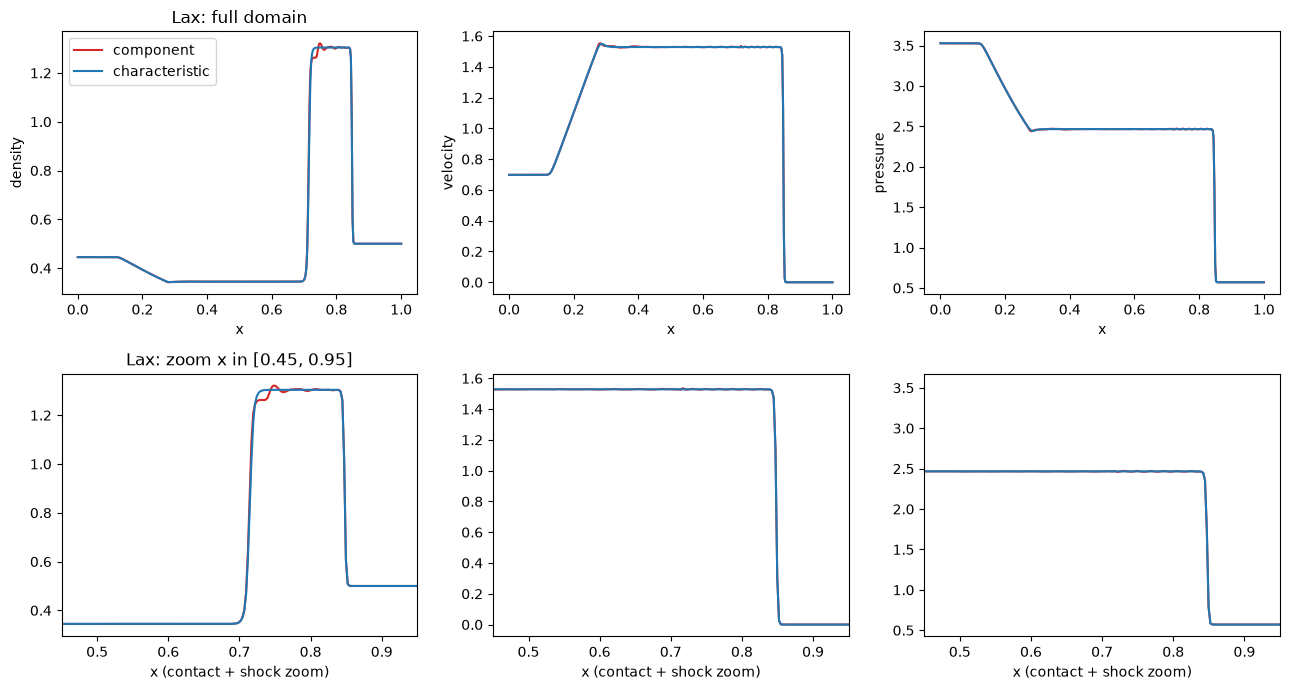

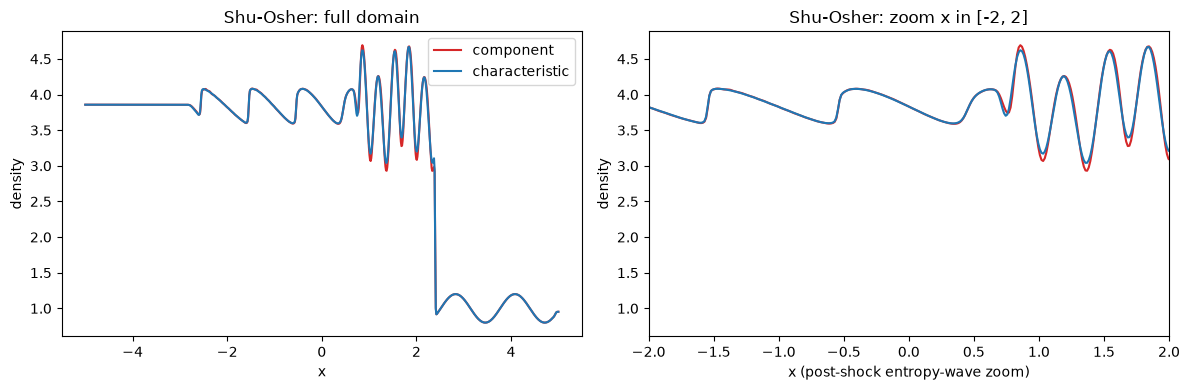

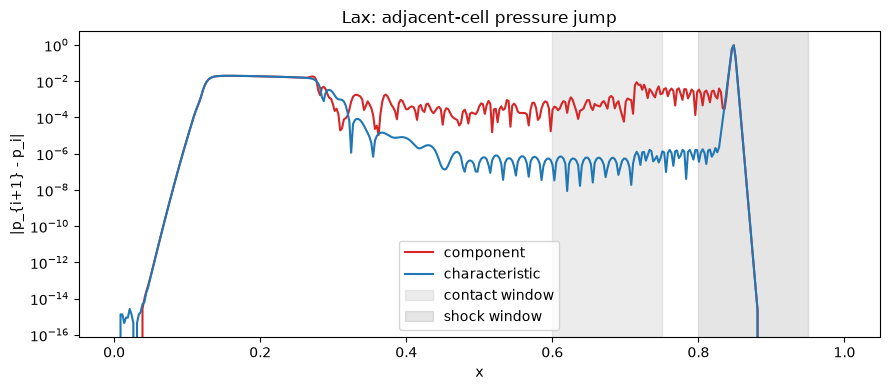

component      max|dp| contact[0.6,0.75] = 8.7446e-03   shock[0.8,0.95] = 9.5810e-01
characteristic max|dp| contact[0.6,0.75] = 1.6129e-06   shock[0.8,0.95] = 9.6115e-01
component      smooth       x=+0.006 density-field left weights (w0,w1,w2) = (0.1000, 0.6000, 0.3000)
component      near-shock   x=+2.384 density-field left weights (w0,w1,w2) = (0.9558, 0.0442, 0.0000)
characteristic smooth       x=+0.006 density-field left weights (w0,w1,w2) = (0.1000, 0.6000, 0.3000)
characteristic near-shock   x=+2.384 density-field left weights (w0,w1,w2) = (0.1910, 0.8087, 0.0002)


In [7]:
CONTACT_WINDOW = (0.60, 0.75)
SHOCK_WINDOW = (0.80, 0.95)
colors = {"component": "tab:red", "characteristic": "tab:blue"}

# --- 1. Lax profiles with contact/shock zooms ---
x_lax, U0_lax = lax_initial_condition(400)
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for mode in MODES:
    rho, u, p, c = conservative_to_primitive(results[("lax", mode)]["U"])
    for ax, field, label in zip(axes[0], (rho, u, p), ("density", "velocity", "pressure")):
        ax.plot(x_lax, field, color=colors[mode], label=mode)
        ax.set_xlabel("x"); ax.set_ylabel(label)
    for ax, field in zip(axes[1], (rho, u, p)):
        ax.plot(x_lax, field, color=colors[mode])
        ax.set_xlim(0.45, 0.95)
        ax.set_xlabel("x (contact + shock zoom)")
axes[0, 0].legend()
axes[0, 0].set_title("Lax: full domain")
axes[1, 0].set_title("Lax: zoom x in [0.45, 0.95]")
fig.tight_layout()
plt.show()

# --- 2. Shu-Osher density, full and zoomed ---
x_so, U0_so = shu_osher_initial_condition(800)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for mode in MODES:
    rho, u, p, c = conservative_to_primitive(results[("shu_osher", mode)]["U"])
    axes[0].plot(x_so, rho, color=colors[mode], label=mode)
    axes[1].plot(x_so, rho, color=colors[mode])
axes[0].set_xlabel("x"); axes[0].set_ylabel("density"); axes[0].set_title("Shu-Osher: full domain")
axes[0].legend()
axes[1].set_xlim(-2.0, 2.0)
axes[1].set_xlabel("x (post-shock entropy-wave zoom)"); axes[1].set_ylabel("density")
axes[1].set_title("Shu-Osher: zoom x in [-2, 2]")
fig.tight_layout()
plt.show()

# --- 3. Pressure-oscillation diagnostic (Lax case) ---
fig, ax = plt.subplots(figsize=(9, 4))
jump_report = {}
for mode in MODES:
    rho, u, p, c = conservative_to_primitive(results[("lax", mode)]["U"])
    dp = np.abs(np.diff(p))
    x_mid = 0.5 * (x_lax[:-1] + x_lax[1:])
    ax.plot(x_mid, dp, color=colors[mode], label=mode)
    for win_name, (lo, hi) in (("contact", CONTACT_WINDOW), ("shock", SHOCK_WINDOW)):
        mask = (x_mid >= lo) & (x_mid <= hi)
        jump_report[(mode, win_name)] = dp[mask].max() if mask.any() else float("nan")
ax.axvspan(*CONTACT_WINDOW, color="gray", alpha=0.15, label="contact window")
ax.axvspan(*SHOCK_WINDOW, color="black", alpha=0.10, label="shock window")
ax.set_xlabel("x"); ax.set_ylabel("|p_{i+1} - p_i|"); ax.set_yscale("log")
ax.set_title("Lax: adjacent-cell pressure jump")
ax.legend()
fig.tight_layout()
plt.show()

for mode in MODES:
    print(
        f"{mode:14s} max|dp| contact[{CONTACT_WINDOW[0]},{CONTACT_WINDOW[1]}] = "
        f"{jump_report[(mode, 'contact')]:.4e}   "
        f"shock[{SHOCK_WINDOW[0]},{SHOCK_WINDOW[1]}] = {jump_report[(mode, 'shock')]:.4e}"
    )

# --- 4. WENO nonlinear weights: smooth entropy-wave vs near-shock interface (Shu-Osher) ---
# At t=1.8 the leading shock has propagated well away from its x=-4 initial
# location (to x~2.4 for N=800); locate its current position from the
# component-mode density jump rather than reusing the initial coordinate.
rho_comp, _, _, _ = conservative_to_primitive(results[("shu_osher", "component")]["U"])
nearshock_i = int(np.argmax(np.abs(np.diff(rho_comp))))
smooth_i = int(np.searchsorted(x_so, 0.0))  # well inside the smooth sinusoidal region
for mode in MODES:
    Ug = _pad_ghost(results[("shu_osher", mode)]["U"])
    _, _, weights = reconstruct_interfaces(Ug, mode, want_weights=True)
    for label, i in (("smooth", smooth_i), ("near-shock", nearshock_i)):
        w_rho = weights[i, 0, :]
        print(f"{mode:14s} {label:12s} x={x_so[i]:+.3f} density-field left weights (w0,w1,w2) = "
              f"({w_rho[0]:.4f}, {w_rho[1]:.4f}, {w_rho[2]:.4f})")


## 6. Automatic checks

Assert:

- Scalar WENO-Z exactly reconstructs constants to machine precision; mirrored left/right tests pass.
- $\|LR-I\|_\infty<10^{-12}$ for at least 20 seeded physical Roe-state pairs.
- Constant Euler states remain constant for both reconstruction modes after 20 steps to below $10^{-12}$ relative error.
- Every accepted stage has finite $\rho,p$ above the floors.
- Final times are reached exactly to roundoff and both modes use the same time-step rule.
- Mass, momentum, and energy changes agree with accumulated numerical boundary flux to below $10^{-10}$ relative scale.
- Both methods use the same Rusanov flux and SSPRK3 implementation; only reconstruction space changes.
- All fallback events are reported. Zero fallback is acceptable; an unreported fallback is not.

Do not add a mesh sweep. These checks target algebra, free-stream preservation, conservation, and physical admissibility on fixed grids.

In [8]:
assert abs(val_l - 3.0) < 1e-13 and abs(val_r - 3.0) < 1e-13
assert abs(val_a - val_b) < 1e-13
assert lr_err < 1e-12

for case_name in CASES:
    for mode in MODES:
        res = results[(case_name, mode)]
        assert np.isfinite(res["U"]).all()
        rho_f, u_f, p_f, c_f = conservative_to_primitive(res["U"])
        assert rho_f.min() > RHO_FLOOR and p_f.min() > P_FLOOR
        assert res["closure"]["mass"] < 1e-10
        assert res["closure"]["mom"] < 1e-10
        assert res["closure"]["energy"] < 1e-10
        assert isinstance(res["fallback"], int) and res["fallback"] >= 0

print("All automatic success checks passed.")


All automatic success checks passed.


## 7. Discussion and next steps

Answer briefly:

1. Why can component-wise reconstruction mix waves that travel at different characteristic speeds?
2. Why is one interface-local Roe basis frozen across the reconstruction stencil?
3. Where does characteristic reconstruction materially reduce pressure ringing, and where is it merely more expensive?
4. How do WENO-Z weights distinguish a smooth entropy wave from a discontinuity?
5. Why is a stage-level first-order fallback robust but overly dissipative?

**Stretch goal (15-25 minutes):** Replace the stage-level fallback with local flux fallback only at interfaces adjacent to nonphysical candidate cells. Recheck conservation closure. Alternatively, add WENO-JS weights while keeping characteristic projection fixed and compare critical-point behavior without changing the grid.

### References

- **Core implementation reference:** Chi-Wang Shu, *Essentially Non-Oscillatory and Weighted Essentially Non-Oscillatory Schemes for Hyperbolic Conservation Laws*, NASA/CR-97-206253, ICASE Report 97-65, 1997. [NASA report](https://ntrs.nasa.gov/search.jsp?R=19980007543).
- Rafael Borges, Monique Carmona, Bruno Costa, and Wai-Sun Don, "An Improved Weighted Essentially Non-Oscillatory Scheme for Hyperbolic Conservation Laws," *Journal of Computational Physics* 227(6), 3191-3211, 2008. [DOI](https://doi.org/10.1016/j.jcp.2007.11.038).
- **NASA Glenn robustness reference:** H. T. Huynh, "Shock Capturing via Limiting for High-Order Methods including Discontinuous Galerkin," 2024. [NASA Glenn NTRS record](https://ntrs.nasa.gov/citations/20240006106).

### Topic ledger

| Date | Primary objective |
|---|---|
| 2026-10-06 | Fixed-mesh advection: CFL, conservation, positivity, TV |
| 2026-10-07 | Krylov methods and line-block preconditioning |
| 2026-10-08 | Data layout, cache behavior, flux-kernel throughput |
| 2026-10-09 | Nonlinear natural-circulation thermal-fluid modeling |
| 2026-10-12 | Discrete-adjoint PDE-constrained optimization |
| 2026-10-13 | Partitioned multiphysics coupling and relaxation |
| 2026-10-14 | Characteristic high-order shock-capturing reconstruction |

All seven immediately preceding/current dated objectives are distinct. This is assignment 6 of the ten-assignment grid-study exclusion; four excluded assignments remain after today. Planned next objectives: parallel algorithms, time integration, uncertainty propagation, and turbulence modeling.